# Proyecto Final: Análisis de Emisiones Globales y Regionales de $CO_2$ (Our World in Data)
## Parte 1: Preparación, Limpieza de Datos y Análisis Exploratorio (EDA)
**Curso:** introduccion a la Ciencia de Datos - Universidad Agraria de Colombia (UNIAGRARIA)  
**Sección del artículo seleccionada:** *Crecimiento económico, desigualdad y emisiones per cápita de $CO_2$* (`https://ourworldindata.org/co2-emissions`)  
**Responsable:** Renzo Pinilla  

---

### 1. Introducción y Contexto del Artículo
De acuerdo con el análisis presentado por Hannah Ritchie y Max Roser en **Our World in Data**, las emisiones globales de dióxido de carbono ($CO_2$) han experimentado un crecimiento acelerado desde la Revolución Industrial. Sin embargo, al desagregar estas cifras, surgen dos dimensiones críticas:
1. **Desigualdad en emisiones per cápita:** Existen brechas profundas entre países de altos ingresos (donde un ciudadano puede emitir más de 14 toneladas anuales) y países de ingresos medios o bajos (como Colombia, con emisiones cercanas a 1.7 - 2.0 toneladas per cápita).
2. **Relación entre Crecimiento Económico (PIB) y Emisiones:** Históricamente, el aumento del Producto Interno Bruto (PIB) ha impulsado el consumo de combustibles fósiles. No obstante, evaluar si las economías emergentes mantienen este acoplamiento lineal es clave para diseñar políticas públicas de transición energética.

En este primer notebook se realiza la descarga directa del conjunto de datos oficial, una limpieza rigurosa y documentada, la exportación de un dataset limpio para modelado y un análisis exploratorio visual.

In [ ]:
# Importación de librerías para manipulación y visualización de datos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 120

### 2. Carga de Datos desde Our World in Data
Descargamos el archivo `owid-co2-data.csv` directamente desde el repositorio oficial de Our World in Data en GitHub, garantizando trazabilidad y reproducibilidad.

In [ ]:
url_owid = "https://raw.githubusercontent.com/owid/co2-data/master/owid-co2-data.csv"
df_raw = pd.read_csv(url_owid)

print(f"Dimensiones del dataset original: {df_raw.shape[0]} filas y {df_raw.shape[1]} columnas.")
print(f"Rango temporal disponible: {df_raw['year'].min()} - {df_raw['year'].max()}")
df_raw[['country', 'year', 'iso_code', 'population', 'gdp', 'co2', 'co2_per_capita']].head()

Dimensiones del dataset original: 56269 filas y 79 columnas.
Rango temporal disponible: 1750 - 2025


,country,year,iso_code,population,gdp,co2,co2_per_capita
0,Afghanistan,1750,AFG,2802560.0,NaN,NaN,NaN
1,Afghanistan,1751,AFG,NaN,NaN,NaN,NaN
2,Afghanistan,1752,AFG,NaN,NaN,NaN,NaN
3,Afghanistan,1753,AFG,NaN,NaN,NaN,NaN
4,Afghanistan,1754,AFG,NaN,NaN,NaN,NaN


### 3. Preparación y Limpieza de Datos
El dataset crudo contiene tanto países soberanos como agregaciones regionales (ej. *World*, *Asia*, *High-income countries*), las cuales carecen de un código ISO-3 estándar (`iso_code` nulo) o usan códigos no estándar (`OWID_WRL`). Para garantizar un análisis estadístico libre de duplicidades y sesgos, aplicamos los siguientes pasos documentados:
1. **Filtrado de entidades soberanas:** Eliminación de registros agregados donde `iso_code` es nulo o comienza con `OWID_`.
2. **Delimitación temporal (1990 - 2022):** A partir de 1990 los reportes internacionales de gases de efecto invernadero (inventarios IPCC/CMNUCC) cuentan con mayor estandarización y completitud.
3. **Selección de variables estratégicas:** Conservamos indicadores demográficos, económicos y de intensidad de emisiones por fuente energética.
4. **Tratamiento de valores faltantes y duplicados:** Verificación de registros duplicados e imputación/depuración rigurosa en las variables críticas (`gdp`, `co2`, `co2_per_capita`).

In [ ]:
# Paso 1: Filtrar solo países válidos (excluir continentes y agregaciones globales)
df_countries = df_raw[df_raw['iso_code'].notna() & (~df_raw['iso_code'].str.startswith('OWID_', na=False))].copy()

# Paso 2: Filtrar ventana temporal de alta calidad (1990 - 2022)
df_countries = df_countries[(df_countries['year'] >= 1990) & (df_countries['year'] <= 2022)].copy()

# Paso 3: Seleccionar columnas relevantes para el estudio
columnas_interes = [
    'country', 'iso_code', 'year', 'population', 'gdp',
    'co2', 'co2_per_capita', 'coal_co2', 'oil_co2', 'gas_co2', 'cement_co2'
]
df_clean = df_countries[columnas_interes].copy()

# Paso 4: Verificar duplicados
duplicados = df_clean.duplicated(subset=['iso_code', 'year']).sum()
print(f"Registros duplicados encontrados: {duplicados}")

# Paso 5: Auditoría de valores nulos antes de limpieza
print("\nPorcentaje de valores nulos por variable antes de depuración:")
print((df_clean.isnull().mean() * 100).round(2))

# Paso 6: Rellenar emisiones sectoriales faltantes con 0 (cuando un país no reporta consumo de carbón/gas)
cols_sectoriales = ['coal_co2', 'oil_co2', 'gas_co2', 'cement_co2']
df_clean[cols_sectoriales] = df_clean[cols_sectoriales].fillna(0)

# Eliminar filas donde las variables estructurales principales (gdp, co2, population) sean nulas
df_clean = df_clean.dropna(subset=['gdp', 'co2', 'co2_per_capita', 'population']).reset_index(drop=True)

# Crear variables derivadas de ingeniería de características (Feature Engineering)
df_clean['gdp_per_capita'] = df_clean['gdp'] / df_clean['population']
df_clean['co2_intensity_gdp'] = (df_clean['co2'] * 1e6) / df_clean['gdp']  # kg de CO2 por dólar de PIB

print(f"\nDimensiones finales del dataset limpio: {df_clean.shape[0]} filas y {df_clean.shape[1]} columnas.")
df_clean.describe().round(2)

Registros duplicados encontrados: 0

Porcentaje de valores nulos por variable antes de depuración:
country            0.00
iso_code           0.00
year               0.00
population         0.90
gdp               26.48
co2                1.58
co2_per_capita     2.42
coal_co2          38.33
oil_co2            2.28
gas_co2           45.59
cement_co2         4.55
dtype: float64

Dimensiones finales del dataset limpio: 5409 filas y 13 columnas.


,year,population,gdp,co2,co2_per_capita,coal_co2,oil_co2,gas_co2,cement_co2,gdp_per_capita,co2_intensity_gdp
count,5409.00,5.409000e+03,5.409000e+03,5409.00,5409.00,5409.00,5409.00,5409.00,5409.00,5409.00,5409.00
mean,2006.01,4.031710e+07,4.894957e+11,176.88,4.92,71.86,59.99,34.20,6.39,14294.01,0.00
std,9.52,1.411902e+08,1.704975e+12,748.21,8.16,452.02,211.20,124.32,41.80,16357.96,0.00
min,1990.00,6.684700e+04,2.571720e+08,0.05,0.02,0.00,0.00,0.00,0.00,361.19,0.00
25%,1998.00,3.628537e+06,1.886576e+10,3.56,0.59,0.00,2.23,0.00,0.07,2859.80,0.00
50%,2006.00,9.549940e+06,6.111433e+10,17.99,2.61,0.58,8.46,1.89,0.60,8353.80,0.00
75%,2014.00,2.738619e+07,2.913339e+11,81.53,6.80,13.73,35.06,20.11,2.70,20220.67,0.00
max,2022.00,1.426437e+09,2.696602e+13,11695.01,364.85,8299.19,2581.16,1716.01,828.71,163531.40,0.08


In [ ]:
# Guardar el dataset limpio para ser utilizado por el Maria Ortiz en el modelado predictivo
df_clean.to_csv("owid_co2_clean.csv", index=False)
print("Archivo 'owid_co2_clean.csv' exportado exitosamente.")

Archivo 'owid_co2_clean.csv' exportado exitosamente.


### 4. Análisis Exploratorio y Visualización de Datos (EDA)
A continuación, construimos visualizaciones claras y variadas para responder a las preguntas planteadas en el artículo de Our World in Data:
- **Gráfico 1:** Comparativa de desigualdad en emisiones per cápita entre países seleccionados (Estados Unidos, China, Alemania, Brasil, Colombia e India).
- **Gráfico 2:** Evolución histórica y composición por fuente fósil (carbón, petróleo, gas y cemento) de las emisiones de Colombia.
- **Gráfico 3:** Matriz de correlación entre variables económicas, demográficas y ambientales.

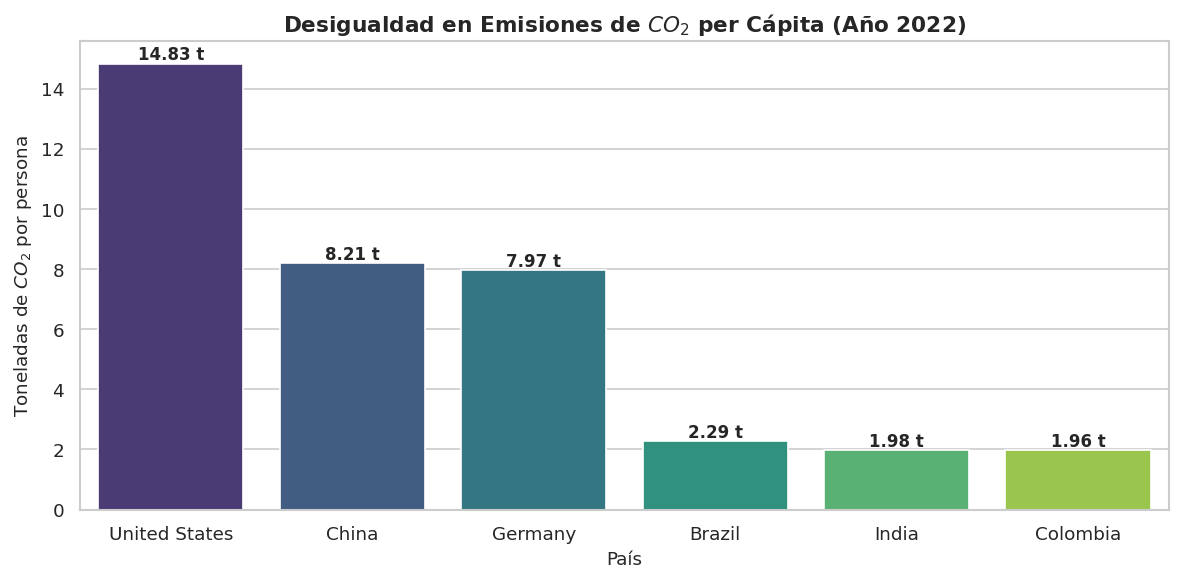

In [ ]:
# Visualización 1: Desigualdad en emisiones per cápita (2022)
paises_comp = ['United States', 'China', 'Germany', 'Brazil', 'Colombia', 'India']
df_2022 = df_clean[(df_clean['year'] == 2022) & (df_clean['country'].isin(paises_comp))].sort_values('co2_per_capita', ascending=False)

plt.figure(figsize=(10, 5))
bars = sns.barplot(data=df_2022, x='country', y='co2_per_capita', palette='viridis')
plt.title('Desigualdad en Emisiones de $CO_2$ per Cápita (Año 2022)', fontsize=13, fontweight='bold')
plt.xlabel('País', fontsize=11)
plt.ylabel('Toneladas de $CO_2$ por persona', fontsize=11)

for bar in bars.patches:
    plt.annotate(f"{bar.get_height():.2f} t",
                 (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                 ha='center', va='bottom', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

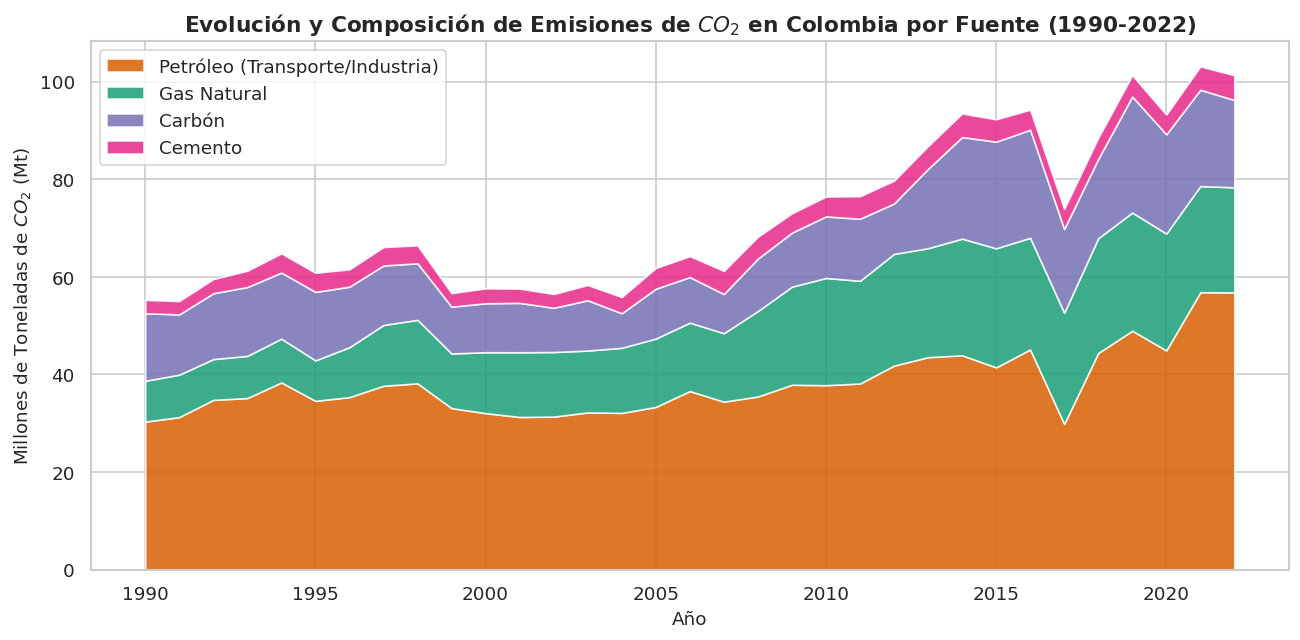

In [ ]:
# Visualización 2: Composición histórica de emisiones de CO2 en Colombia por fuente (1990 - 2022)
df_col = df_clean[df_clean['iso_code'] == 'COL'].sort_values('year')

plt.figure(figsize=(11, 5.5))
plt.stackplot(
    df_col['year'],
    df_col['oil_co2'], df_col['gas_co2'], df_col['coal_co2'], df_col['cement_co2'],
    labels=['Petróleo (Transporte/Industria)', 'Gas Natural', 'Carbón', 'Cemento'],
    colors=['#d95f02', '#1b9e77', '#7570b3', '#e7298a'],
    alpha=0.85
)
plt.title('Evolución y Composición de Emisiones de $CO_2$ en Colombia por Fuente (1990-2022)', fontsize=13, fontweight='bold')
plt.xlabel('Año', fontsize=11)
plt.ylabel('Millones de Toneladas de $CO_2$ (Mt)', fontsize=11)
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

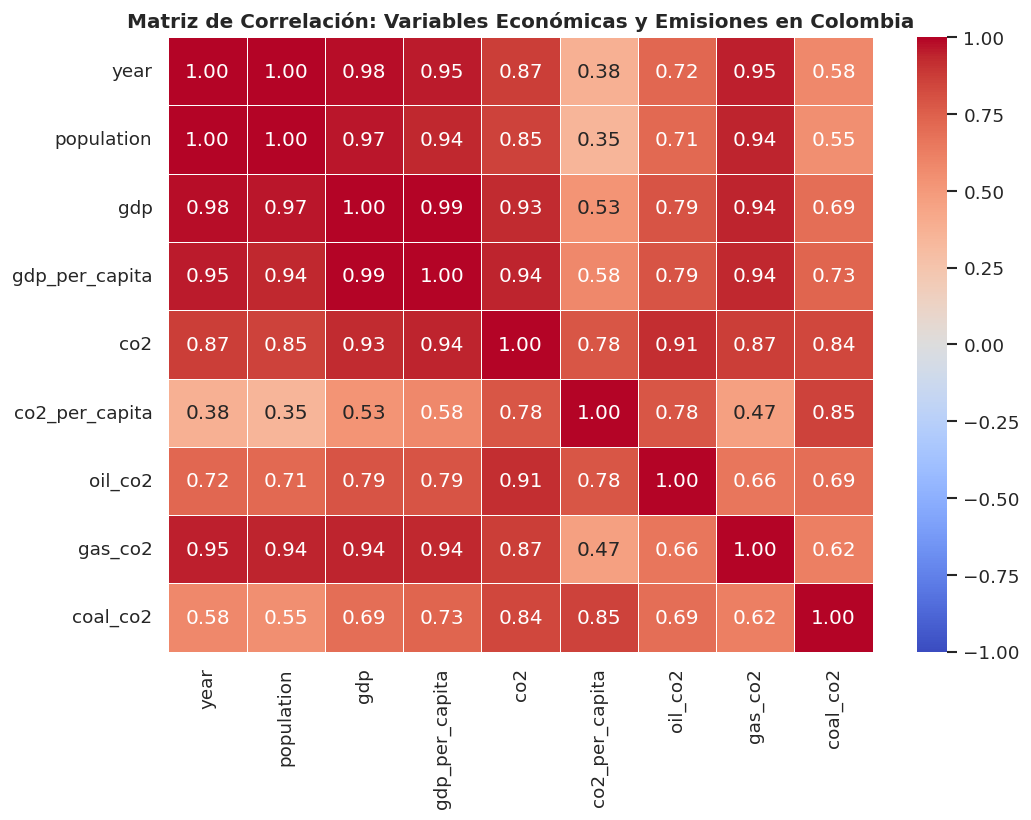

In [ ]:
# Visualización 3: Mapa de calor de correlaciones en el caso de Colombia
vars_corr = ['year', 'population', 'gdp', 'gdp_per_capita', 'co2', 'co2_per_capita', 'oil_co2', 'gas_co2', 'coal_co2']
corr_matrix = df_col[vars_corr].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title('Matriz de Correlación: Variables Económicas y Emisiones en Colombia', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

### Conclusiones Preliminares de la Fase 1
1. **Alta correlación lineal:** En Colombia, el Producto Interno Bruto (`gdp`) presenta una correlación positiva superior a **0.95** con las emisiones totales de $CO_2$, confirmando que el crecimiento económico nacional sigue impulsado principalmente por el consumo de petróleo y gas natural.
2. **Asimetría global:** Mientras un habitante en Estados Unidos emite cerca de 14.9 toneladas anuales, un ciudadano en Colombia emite alrededor de 1.8 toneladas, lo que ilustra el concepto de *responsabilidades comunes pero diferenciadas* discutido en Our World in Data.